# CIFAR-10 with classical ML: HOG features + SVM


---
## 1. Problem Specification

### 1.1 Learning Type
This is a supervised multi-class image classification problem. Given a 32×32 colour image as input, the model must predict one of 10 mutually exclusive object categories. Labels are provided, making this supervised learning.

### 1.2 Dataset
CIFAR-10: 60,000 colour images (32×32×3) across 10 classes:  
airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck  
- Training set: 50,000 images (5,000 per class)  
- Test set: 10,000 images (1,000 per class)  
- Same data partitioning strategy as Task 1 (Deep Learning) for fair comparison in Task 3.

### 1.3 Selected Learning Algorithm
Support Vector Machine (SVM) with an RBF (Radial Basis Function) kernel.

Justification:
- SVM finds optimal decision boundaries in high-dimensional feature spaces via the kernel trick
- The RBF kernel models non-linear class boundaries common in visual data
- Robust against overfitting through regularisation parameter C
- Strong theoretical foundation (maximum margin) and consistently strong performance with structured features like HOG

### 1.4 Hyperparameter to be Optimised
Regularisation parameter controls the trade-off between margin width and training error:
- Low C → wider margin, more misclassifications tolerated (underfitting risk)
- High C → narrower margin, fewer misclassifications (overfitting risk)

We also tune gamma (RBF kernel coefficient) as a secondary hyperparameter using GridSearchCV, since C and gamma jointly determine the decision boundary shape.

### 1.5 Feature Extraction Method
HOG (Histogram of Oriented Gradients): a widely-used feature descriptor for object detection and image classification.

How HOG works:
1. Convert image to grayscale
2. Compute gradient magnitude and direction at each pixel
3. Divide image into small spatial cells (4×4 pixels)
4. For each cell, build a histogram of gradient orientations
5. Normalise histograms across overlapping blocks (2×2 cells) for illumination robustness
6. Concatenate into a single feature vector

Why HOG for CIFAR-10: HOG captures local edge and gradient structure the most discriminative visual cues for distinguishing object shapes. It is robust to small geometric and photometric variations.

Feature vector length: 32×32 image, pixels_per_cell=(4,4), cells_per_block=(2,2): 7 × 7 × 2 × 2 × 9 = 1,764 features per image

### 1.6 Methodology Overview
Stage 1 (Algorithm Selection): Extract HOG features from a stratified sample. Compare three ML algorithms SVM (RBF), Random Forest, and KNN using cross-validation on the training split and evaluation on the held-out validation and test sets.

Stage 2 (Hyperparameter Tuning): Apply GridSearchCV with 5-fold stratified cross-validation on the training set to find optimal C and gamma. Evaluate the final tuned model on the test set.

Optional: Compare HOG against PCA and Color Histograms as feature extraction methods.

### 1.7 Data Partitioning
Consistent with Task 1, we draw a stratified sample of 10,000 images (1,000 per class), then split:
- Training set: 8,000 images (800 per class) for model training and cross-validation
- Validation set: 2,000 images (200 per class) for monitoring generalisation
- Test set: 10,000 images (official CIFAR-10 test split) for final evaluation only

---
## 2. Environment Setup and Imports

In [1]:
# Core libraries
import numpy as np
import pandas as pd
import time
import warnings
warnings.filterwarnings('ignore')

# Data loading
import torchvision

# Feature extraction
from skimage.feature import hog
from skimage.color import rgb2gray
from sklearn.decomposition import PCA

# Machine learning models
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

# Model selection and evaluation
from sklearn.model_selection import GridSearchCV, StratifiedShuffleSplit, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Reproducibility
SEED = 42
np.random.seed(SEED)

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")

print("All libraries imported successfully.")

All libraries imported successfully.


---
## 3. Data Loading and Pre-processing

### 3.1 Load CIFAR-10 Dataset
We use torchvision to download CIFAR-10 (consistent with Task 1) and convert to NumPy arrays for scikit-learn compatibility.

In [2]:
CLASSES = ('airplane', 'automobile', 'bird', 'cat', 'deer',
           'dog', 'frog', 'horse', 'ship', 'truck')
NUM_CLASSES = 10

# Load CIFAR-10
train_dataset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True)
test_dataset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True)

# Convert to NumPy arrays
X_train_all = np.array(train_dataset.data)       # (50000, 32, 32, 3)
y_train_all = np.array(train_dataset.targets)     # (50000,)
X_test_raw = np.array(test_dataset.data)          # (10000, 32, 32, 3)
y_test = np.array(test_dataset.targets)           # (10000,)

print(f"Full training set: {X_train_all.shape} | {len(y_train_all)} labels")
print(f"Test set:          {X_test_raw.shape} | {len(y_test)} labels")
print(f"Image dtype: {X_train_all.dtype}, range [{X_train_all.min()}, {X_train_all.max()}]")
print(f"Classes: {CLASSES}")

100%|██████████| 170M/170M [00:02<00:00, 69.4MB/s]


Full training set: (50000, 32, 32, 3) | 50000 labels
Test set:          (10000, 32, 32, 3) | 10000 labels
Image dtype: uint8, range [0, 255]
Classes: ('airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')


### 3.2 Exploratory Data Visualisation

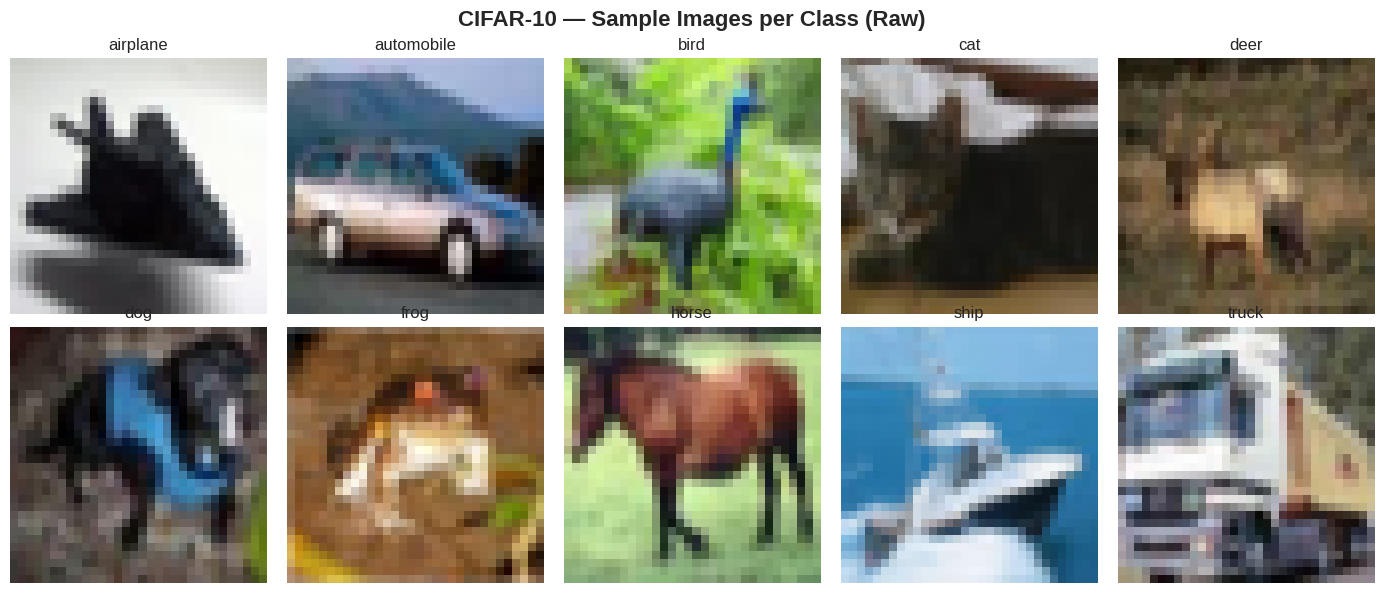

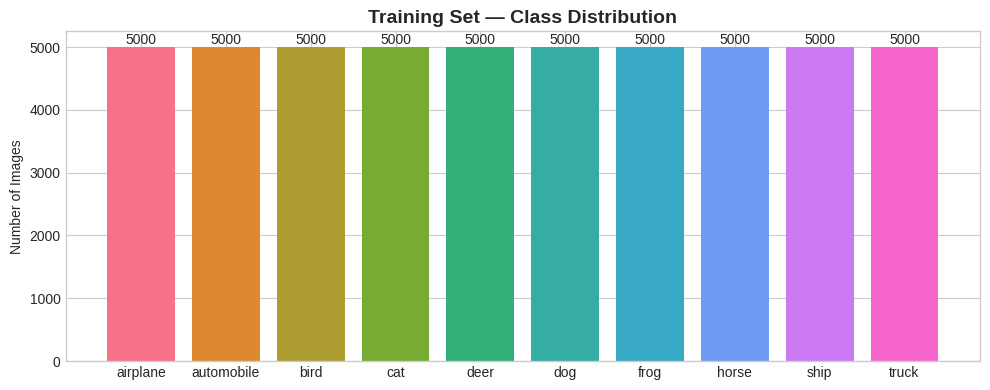

Dataset is balanced: 5,000 images per class.


In [3]:
# Sample images per class
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
fig.suptitle('CIFAR-10 — Sample Images per Class (Raw)', fontsize=16, fontweight='bold')

for class_idx in range(NUM_CLASSES):
    row, col = class_idx // 5, class_idx % 5
    idx = np.where(y_train_all == class_idx)[0][0]
    axes[row, col].imshow(X_train_all[idx])
    axes[row, col].set_title(CLASSES[class_idx], fontsize=12)
    axes[row, col].axis('off')

plt.tight_layout()
plt.show()

# Class distribution
unique, counts = np.unique(y_train_all, return_counts=True)
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(CLASSES, counts, color=sns.color_palette("husl", NUM_CLASSES))
ax.set_title('Training Set — Class Distribution', fontsize=14, fontweight='bold')
ax.set_ylabel('Number of Images')
for i, v in enumerate(counts):
    ax.text(i, v + 50, str(v), ha='center', fontsize=10)
plt.tight_layout()
plt.show()
print("Dataset is balanced: 5,000 images per class.")

---
## 4. Data Partitioning: Train / Validation / Test

Consistent with Task 1, we draw a stratified 10,000-image sample (1,000 per class), then split:
- Training: 8,000 images (800 per class) for model training and GridSearchCV
- Validation: 2,000 images (200 per class) for monitoring generalisation
- Test: 10,000 images for final evaluation only

In [4]:
# Step 1: Draw stratified 10,000-image sample from full training set
sss = StratifiedShuffleSplit(n_splits=1, train_size=10000, random_state=SEED)
sample_indices, _ = next(sss.split(X_train_all, y_train_all))

X_sample = X_train_all[sample_indices]
y_sample = y_train_all[sample_indices]

# Step 2: Split 10k sample into 8k train + 2k validation
sss2 = StratifiedShuffleSplit(n_splits=1, train_size=8000, test_size=2000, random_state=SEED)
train_idx, val_idx = next(sss2.split(X_sample, y_sample))

X_train_raw = X_sample[train_idx]    # 8,000 images
y_train = y_sample[train_idx]
X_val_raw = X_sample[val_idx]        # 2,000 images
y_val = y_sample[val_idx]

# Verify stratification
print("Data Partitioning Summary:")
print(f"{'':>12s}  {'Train':>6s}  {'Val':>5s}  {'Test':>5s}")
print(f"{'─'*38}")
for i, cls in enumerate(CLASSES):
    t = np.sum(y_train == i)
    v = np.sum(y_val == i)
    te = np.sum(y_test == i)
    print(f"{cls:>12s}  {t:>6d}  {v:>5d}  {te:>5d}")
print(f"{'─'*38}")
print(f"{'TOTAL':>12s}  {len(y_train):>6d}  {len(y_val):>5d}  {len(y_test):>5d}")

Data Partitioning Summary:
               Train    Val   Test
──────────────────────────────────────
    airplane     800    200   1000
  automobile     800    200   1000
        bird     800    200   1000
         cat     800    200   1000
        deer     800    200   1000
         dog     800    200   1000
        frog     800    200   1000
       horse     800    200   1000
        ship     800    200   1000
       truck     800    200   1000
──────────────────────────────────────
       TOTAL    8000   2000  10000


---
## 5. Feature Extraction HOG (Histogram of Oriented Gradients)

### 5.1 HOG Pipeline

For 32×32 CIFAR-10 images, we use:
- Grayscale conversion HOG operates on gradient magnitudes
- Orientations = 9 9 orientation bins (0°–180°, unsigned gradients)
- Pixels per cell = (4, 4) Small cells for fine-grained gradients in low-resolution images
- Cells per block = (2, 2) Standard block normalisation for illumination robustness
- Block norm = L2-Hys L2 normalisation with hysteresis clipping

Feature vector: 7 × 7 blocks × 2 × 2 cells × 9 orientations = 1,764 features per image

In [5]:
def extract_hog_features(images, orientations=9, pixels_per_cell=(4, 4),
                         cells_per_block=(2, 2), verbose=True):
    """
    Extract HOG features from a batch of RGB images.

    Parameters:
        images (np.array): Shape (N, 32, 32, 3), uint8
        orientations (int): Number of orientation bins
        pixels_per_cell (tuple): Cell size in pixels
        cells_per_block (tuple): Block size in cells
        verbose (bool): Print progress

    Returns:
        features (np.array): Shape (N, feature_dim)
    """
    n = len(images)
    features = []
    start = time.time()

    for i in range(n):
        gray = rgb2gray(images[i])  # (32, 32), float64 [0, 1]
        feat = hog(gray, orientations=orientations, pixels_per_cell=pixels_per_cell,
                   cells_per_block=cells_per_block, block_norm='L2-Hys', feature_vector=True)
        features.append(feat)
        if verbose and (i + 1) % 2000 == 0:
            print(f"  Processed {i+1:,}/{n:,} images ({time.time()-start:.1f}s)")

    features = np.array(features)
    if verbose:
        print(f"  Done: {features.shape} in {time.time()-start:.1f}s")
    return features

### 5.2 HOG Visualisation

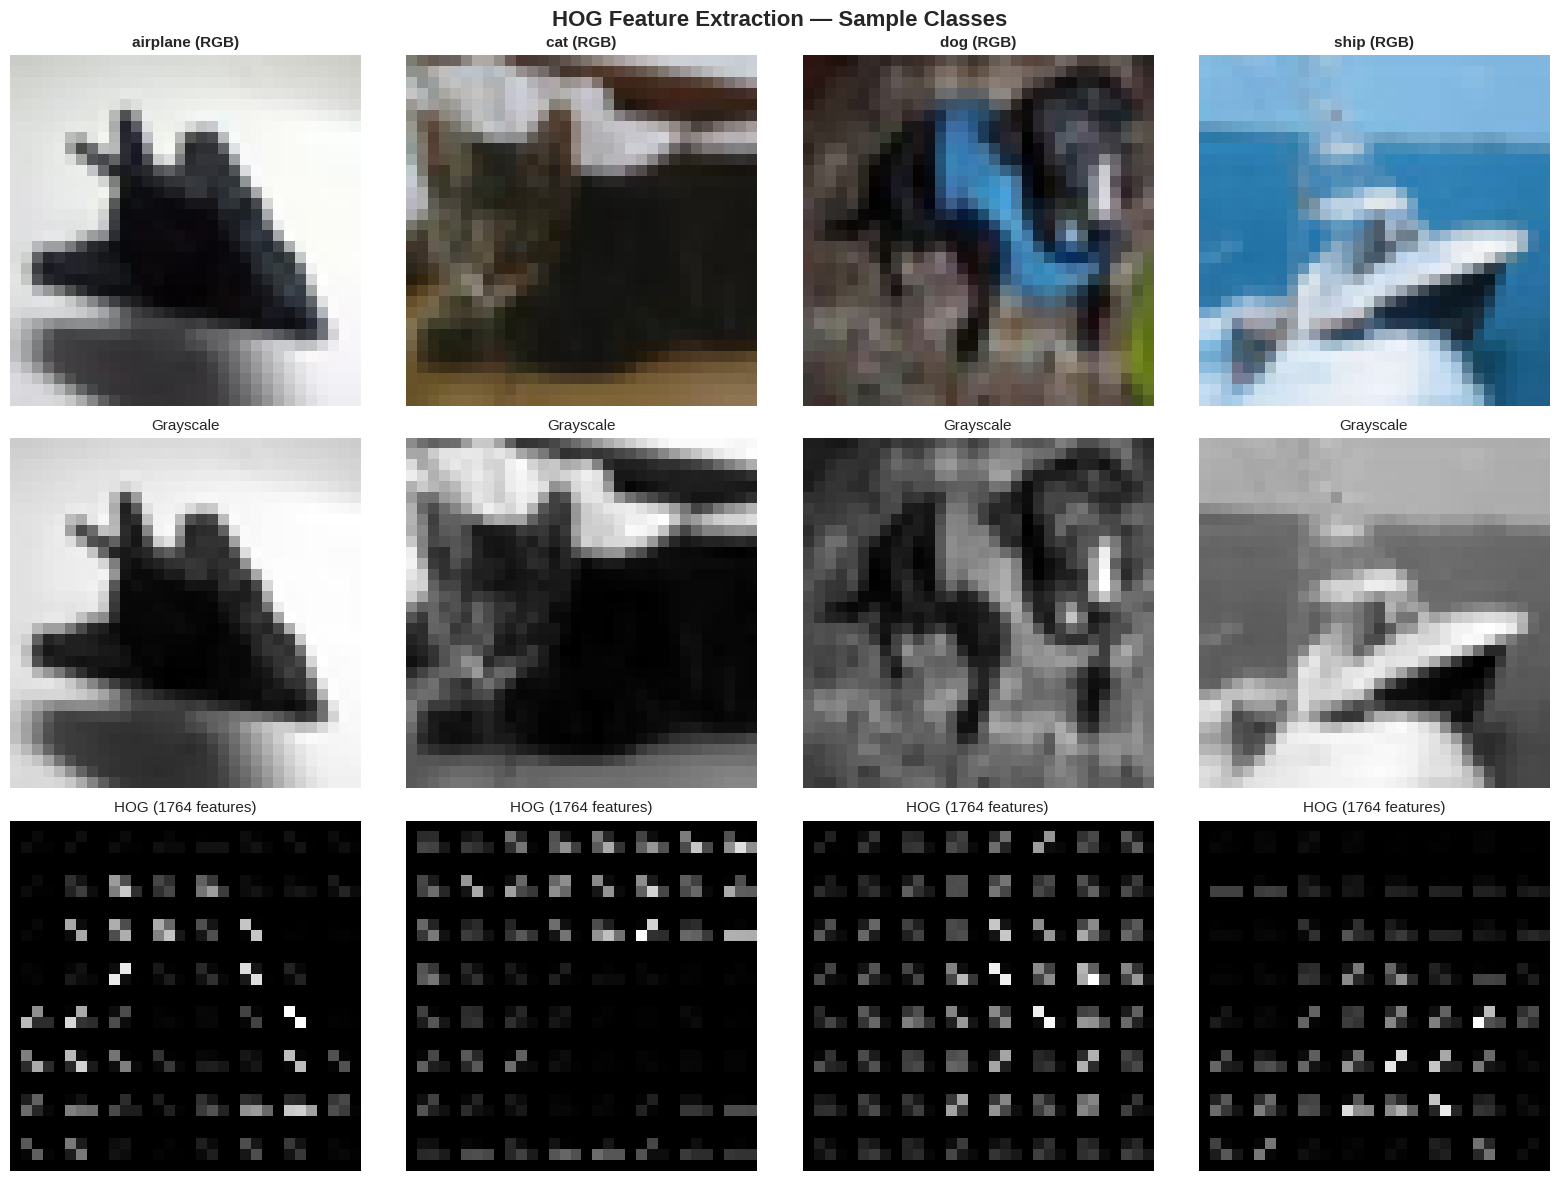

HOG feature vector length: 1764


In [6]:
# Visualise HOG for sample images from different classes
fig, axes = plt.subplots(3, 4, figsize=(16, 12))
fig.suptitle('HOG Feature Extraction — Sample Classes', fontsize=16, fontweight='bold')

sample_classes = [0, 3, 5, 8]  # airplane, cat, dog, ship
for col, cls_idx in enumerate(sample_classes):
    img_idx = np.where(y_train_all == cls_idx)[0][0]
    img = X_train_all[img_idx]
    gray = rgb2gray(img)

    hog_feat, hog_img = hog(gray, orientations=9, pixels_per_cell=(4, 4),
                             cells_per_block=(2, 2), block_norm='L2-Hys',
                             visualize=True, feature_vector=True)

    axes[0, col].imshow(img)
    axes[0, col].set_title(f'{CLASSES[cls_idx]} (RGB)', fontsize=11, fontweight='bold')
    axes[0, col].axis('off')

    axes[1, col].imshow(gray, cmap='gray')
    axes[1, col].set_title('Grayscale', fontsize=11)
    axes[1, col].axis('off')

    axes[2, col].imshow(hog_img, cmap='gray')
    axes[2, col].set_title(f'HOG ({len(hog_feat)} features)', fontsize=11)
    axes[2, col].axis('off')

plt.tight_layout()
plt.show()
print(f"HOG feature vector length: {len(hog_feat)}")

### 5.3 Extract HOG Features from All Splits

In [7]:
# Extract HOG features
print("Extracting HOG features from training set (8,000 images)...")
X_train_hog = extract_hog_features(X_train_raw)

print("\nExtracting HOG features from validation set (2,000 images)...")
X_val_hog = extract_hog_features(X_val_raw)

print("\nExtracting HOG features from test set (10,000 images)...")
X_test_hog = extract_hog_features(X_test_raw)

print(f"\nTrain HOG: {X_train_hog.shape}")
print(f"Val HOG:   {X_val_hog.shape}")
print(f"Test HOG:  {X_test_hog.shape}")

Extracting HOG features from training set (8,000 images)...
  Processed 2,000/8,000 images (3.4s)
  Processed 4,000/8,000 images (6.9s)
  Processed 6,000/8,000 images (9.3s)
  Processed 8,000/8,000 images (11.8s)
  Done: (8000, 1764) in 11.8s

Extracting HOG features from validation set (2,000 images)...
  Processed 2,000/2,000 images (2.4s)
  Done: (2000, 1764) in 2.4s

Extracting HOG features from test set (10,000 images)...
  Processed 2,000/10,000 images (3.0s)
  Processed 4,000/10,000 images (6.0s)
  Processed 6,000/10,000 images (8.4s)
  Processed 8,000/10,000 images (10.9s)
  Processed 10,000/10,000 images (13.4s)
  Done: (10000, 1764) in 13.4s

Train HOG: (8000, 1764)
Val HOG:   (2000, 1764)
Test HOG:  (10000, 1764)


### 5.4 Feature Scaling
Feature scaling is essential for distance-based algorithms (SVM, KNN). We fit StandardScaler on training data only, then transform all splits to prevent data leakage.

In [8]:
# Fit scaler on training set ONLY, transform all splits
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_hog)
X_val_scaled = scaler.transform(X_val_hog)
X_test_scaled = scaler.transform(X_test_hog)

print(f"Scaled train — Mean: {X_train_scaled.mean():.6f}, Std: {X_train_scaled.std():.6f}")
print(f"Scaled val   — Mean: {X_val_scaled.mean():.6f}, Std: {X_val_scaled.std():.6f}")
print(f"Scaled test  — Mean: {X_test_scaled.mean():.6f}, Std: {X_test_scaled.std():.6f}")

Scaled train — Mean: 0.000000, Std: 1.000000
Scaled val   — Mean: 0.001640, Std: 0.999037
Scaled test  — Mean: 0.000511, Std: 1.000029


---
## 6. Stage 1: Algorithm Comparison

We compare three ML algorithms using HOG features on the 8,000-image training set:

| Algorithm | Type | Key Strengths |
|-----------|------|---------------|
| **SVM (RBF)** | Margin-based | Optimal hyperplane; non-linear via kernel trick |
| **Random Forest** | Ensemble (Bagging) | Robust to noise; handles feature interactions |
| **KNN** | Instance-based | Simple, non-parametric; effective for well-separated clusters |

Each model is trained on 8k, validated on 2k, and tested on 10k.

In [9]:
def train_and_evaluate(model, X_tr, y_tr, X_val, y_val, X_te, y_te, name="Model"):
    """Train, validate, and test an ML model. Returns metrics and predictions."""
    print(f"\n{'='*60}")
    print(f"  Training: {name}")
    print(f"{'='*60}")

    start = time.time()
    model.fit(X_tr, y_tr)
    train_time = time.time() - start

    # Validation performance
    val_pred = model.predict(X_val)
    val_acc = accuracy_score(y_val, val_pred)

    # Test performance
    test_pred = model.predict(X_te)
    acc = accuracy_score(y_te, test_pred)
    prec = precision_score(y_te, test_pred, average='weighted')
    rec = recall_score(y_te, test_pred, average='weighted')
    f1 = f1_score(y_te, test_pred, average='weighted')

    metrics = {'model': name, 'val_accuracy': val_acc, 'accuracy': acc,
               'precision': prec, 'recall': rec, 'f1_score': f1, 'train_time': train_time}

    print(f"  Train time: {train_time:.1f}s")
    print(f"  Val Accuracy:  {val_acc:.4f} ({val_acc*100:.2f}%)")
    print(f"  Test Accuracy: {acc:.4f} ({acc*100:.2f}%)")
    print(f"  Precision: {prec:.4f} | Recall: {rec:.4f} | F1: {f1:.4f}")
    print(f"{'='*60}")

    return model, metrics, test_pred

### 6.1 SVM (RBF Kernel)

In [10]:
svm_model = SVC(kernel='rbf', C=1.0, gamma='scale', random_state=SEED)
svm_model, svm_metrics, svm_preds = train_and_evaluate(
    svm_model, X_train_scaled, y_train, X_val_scaled, y_val,
    X_test_scaled, y_test, "SVM (RBF Kernel)"
)


  Training: SVM (RBF Kernel)
  Train time: 98.8s
  Val Accuracy:  0.5650 (56.50%)
  Test Accuracy: 0.5335 (53.35%)
  Precision: 0.5349 | Recall: 0.5335 | F1: 0.5328


### 6.2 Random Forest

In [11]:
rf_model = RandomForestClassifier(
    n_estimators=300, max_depth=None, min_samples_split=5,
    random_state=SEED, n_jobs=-1
)
rf_model, rf_metrics, rf_preds = train_and_evaluate(
    rf_model, X_train_scaled, y_train, X_val_scaled, y_val,
    X_test_scaled, y_test, "Random Forest"
)


  Training: Random Forest
  Train time: 97.9s
  Val Accuracy:  0.4570 (45.70%)
  Test Accuracy: 0.4408 (44.08%)
  Precision: 0.4354 | Recall: 0.4408 | F1: 0.4303


### 6.3 K-Nearest Neighbours

In [12]:
knn_model = KNeighborsClassifier(n_neighbors=5, weights='distance', n_jobs=-1)
knn_model, knn_metrics, knn_preds = train_and_evaluate(
    knn_model, X_train_scaled, y_train, X_val_scaled, y_val,
    X_test_scaled, y_test, "KNN (k=5)"
)


  Training: KNN (k=5)
  Train time: 0.0s
  Val Accuracy:  0.4385 (43.85%)
  Test Accuracy: 0.4103 (41.03%)
  Precision: 0.4730 | Recall: 0.4103 | F1: 0.4031


---
## 7. Stage 1 Algorithm Comparison and Selection

In [13]:
# Comparison table
comp_df = pd.DataFrame([svm_metrics, rf_metrics, knn_metrics]).set_index('model')

print("=" * 80)
print("  Stage 1 — Algorithm Comparison (HOG features, 8k train / 2k val / 10k test)")
print("=" * 80)
print(comp_df.to_string(float_format='{:.4f}'.format))
print()

best_algo_name = comp_df['accuracy'].idxmax()
best_algo_acc = comp_df['accuracy'].max()
print(f"  ★ Best algorithm: {best_algo_name} (Test Accuracy: {best_algo_acc:.4f})")
print("=" * 80)

  Stage 1 — Algorithm Comparison (HOG features, 8k train / 2k val / 10k test)
                  val_accuracy  accuracy  precision  recall  f1_score  train_time
model                                                                            
SVM (RBF Kernel)        0.5650    0.5335     0.5349  0.5335    0.5328     98.7679
Random Forest           0.4570    0.4408     0.4354  0.4408    0.4303     97.9497
KNN (k=5)               0.4385    0.4103     0.4730  0.4103    0.4031      0.0144

  ★ Best algorithm: SVM (RBF Kernel) (Test Accuracy: 0.5335)


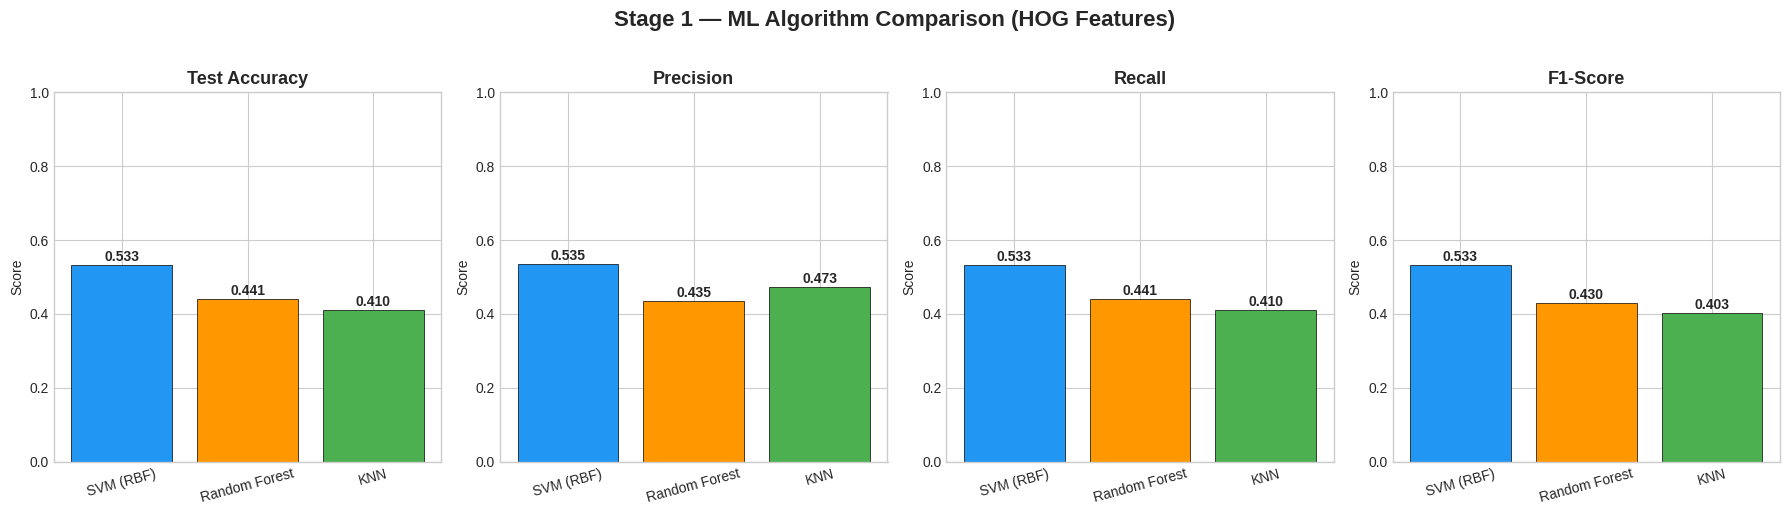

In [14]:
# Bar chart comparison
fig, axes = plt.subplots(1, 4, figsize=(18, 5))
plot_metrics = ['accuracy', 'precision', 'recall', 'f1_score']
plot_labels = ['Test Accuracy', 'Precision', 'Recall', 'F1-Score']
colors = ['#2196F3', '#FF9800', '#4CAF50']
model_names = ['SVM (RBF)', 'Random Forest', 'KNN']

for i, (metric, label) in enumerate(zip(plot_metrics, plot_labels)):
    values = comp_df[metric].values
    bars = axes[i].bar(model_names, values, color=colors, edgecolor='black', linewidth=0.5)
    axes[i].set_title(label, fontsize=13, fontweight='bold')
    axes[i].set_ylim(0, 1.0)
    axes[i].set_ylabel('Score')
    axes[i].tick_params(axis='x', rotation=15)
    for bar, val in zip(bars, values):
        axes[i].text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.01,
                     f'{val:.3f}', ha='center', fontsize=10, fontweight='bold')

fig.suptitle('Stage 1 — ML Algorithm Comparison (HOG Features)', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

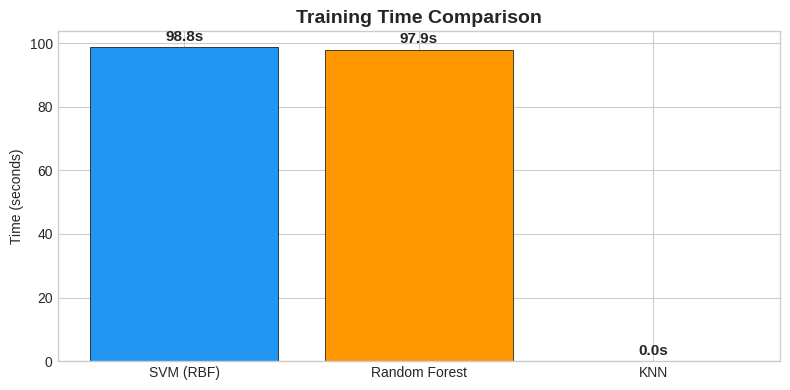

In [15]:
# Training time comparison
fig, ax = plt.subplots(figsize=(8, 4))
times = comp_df['train_time'].values
bars = ax.bar(model_names, times, color=colors, edgecolor='black', linewidth=0.5)
ax.set_title('Training Time Comparison', fontsize=14, fontweight='bold')
ax.set_ylabel('Time (seconds)')
for bar, val in zip(bars, times):
    ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + max(times)*0.02,
            f'{val:.1f}s', ha='center', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

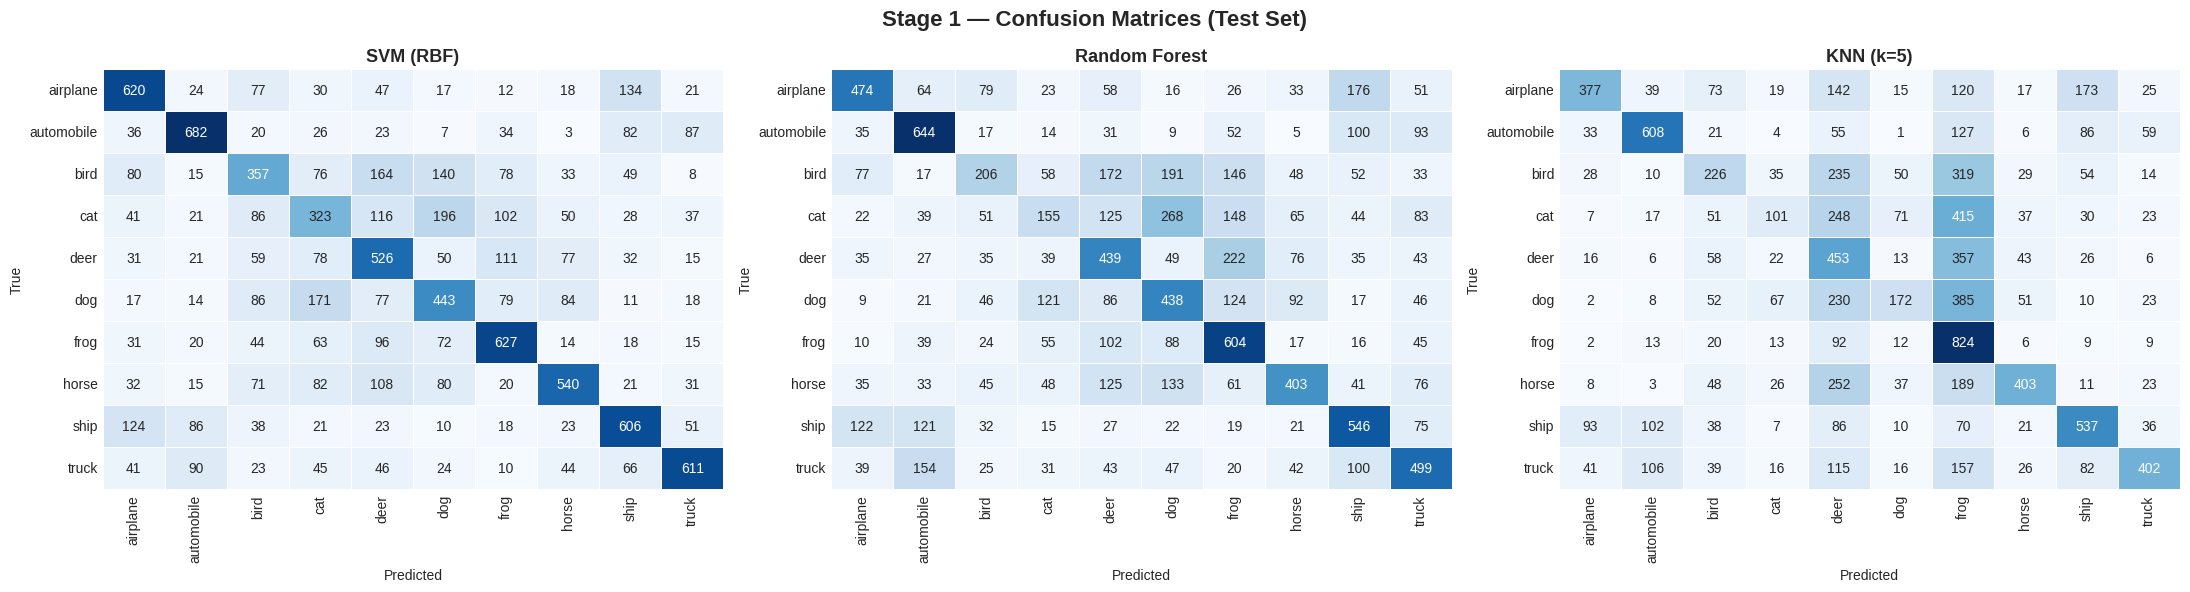

In [16]:
# Confusion matrices — side by side
fig, axes = plt.subplots(1, 3, figsize=(22, 6))
all_preds = [svm_preds, rf_preds, knn_preds]
display_names = ['SVM (RBF)', 'Random Forest', 'KNN (k=5)']

for i, (preds, name) in enumerate(zip(all_preds, display_names)):
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASSES,
                yticklabels=CLASSES, ax=axes[i], linewidths=0.5, cbar=False)
    axes[i].set_title(name, fontsize=13, fontweight='bold')
    axes[i].set_xlabel('Predicted'); axes[i].set_ylabel('True')

fig.suptitle('Stage 1 — Confusion Matrices (Test Set)', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

In [17]:
# Per-class classification reports
for name, preds in zip(display_names, all_preds):
    print(f"\n{'='*70}")
    print(f"  {name} — Per-Class Classification Report")
    print(f"{'='*70}")
    print(classification_report(y_test, preds, target_names=CLASSES, digits=4))


  SVM (RBF) — Per-Class Classification Report
              precision    recall  f1-score   support

    airplane     0.5888    0.6200    0.6040      1000
  automobile     0.6903    0.6820    0.6861      1000
        bird     0.4146    0.3570    0.3837      1000
         cat     0.3530    0.3230    0.3373      1000
        deer     0.4290    0.5260    0.4726      1000
         dog     0.4264    0.4430    0.4345      1000
        frog     0.5747    0.6270    0.5997      1000
       horse     0.6095    0.5400    0.5726      1000
        ship     0.5788    0.6060    0.5921      1000
       truck     0.6834    0.6110    0.6452      1000

    accuracy                         0.5335     10000
   macro avg     0.5349    0.5335    0.5328     10000
weighted avg     0.5349    0.5335    0.5328     10000


  Random Forest — Per-Class Classification Report
              precision    recall  f1-score   support

    airplane     0.5524    0.4740    0.5102      1000
  automobile     0.5557    0.6440 